# 01 - Reproduction check: our run of the original code (v0) vs the paper

Compares our full run of the authors' **unmodified** `run.py` (`results/full_run/originalCode_ConstantinGavrila.csv`,
142 datasets x 30 resamples) with the published results in `original/results/`.

**Metric available:** accuracy only. `run.py` records nothing else: no probabilities (so no AUROC or log loss) and no timings.
Those come with the instrumented v1 code (see the plan).

**Principles applied** (reproducibility best practices, see the plan, Part B0):
- all 142 x 30 runs are used and reported; nothing is dropped and no best run is selected
- per-dataset results as mean ± std over the 30 resamples
- effect sizes (mean difference, test cases, W/D/L) next to every p-value
- with 142 datasets some |z| >= 2 happen by chance, so we also apply a Holm correction
- same datasets and same splits (the published resample indices) as the authors
- note: `run.py` is unseeded, so seed noise cannot be separated here (planned in v1)

Questions:
1. Do our accuracies match the published ones, per dataset and resample?
2. Are the differences within the expected noise, or systematic?
3. Do the overall means match the paper: 0.8568 (142 datasets) and 0.8671 (112 original datasets)?

## 1. Settings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

REPO = Path.cwd().parent            # the notebook runs from quant-reproduction/notebooks
RUN_DIR = REPO / "results" / "full_run"
OUR_RESULTS = RUN_DIR / "originalCode_ConstantinGavrila.csv"   # one results file per student
RUN_NAME = OUR_RESULTS.stem                                     # used to name the output tables

PUBLISHED_RESAMPLES = REPO / "original" / "results" / "accuracy_resamples_ucr142.csv"
DATA_TS = REPO / "data" / "ts"

N_DATASETS, N_RESAMPLES = 142, 30
PAPER_MEAN_142 = 0.8568             # Fig. 6
PAPER_MEAN_112 = 0.8671             # Fig. 1

# the 30 datasets added by the bake-off redux (Python resamples); the other 112 are the original UCR datasets (Java resamples)
NEW30 = [
    "AconityMINIPrinterLargeEq", "AconityMINIPrinterSmallEq", "AllGestureWiimoteXEq", "AllGestureWiimoteYEq",
    "AllGestureWiimoteZEq", "AsphaltObstaclesUniEq", "AsphaltPavementTypeUniEq", "AsphaltRegularityUniEq",
    "Colposcopy", "Covid3MonthDiscrete", "DodgerLoopDayNmv", "DodgerLoopGameNmv", "DodgerLoopWeekendNmv",
    "ElectricDeviceDetection", "FloodModeling1Discrete", "FloodModeling2Discrete", "FloodModeling3Discrete",
    "GestureMidAirD1Eq", "GestureMidAirD2Eq", "GestureMidAirD3Eq", "GesturePebbleZ1Eq", "GesturePebbleZ2Eq",
    "KeplerLightCurves", "MelbournePedestrianNmv", "PLAIDEq", "PhoneHeartbeatSound", "PickupGestureWiimoteZEq",
    "ShakeGestureWiimoteZEq", "SharePriceIncrease", "Tools",
]

# datasets corrected after the bake-off pre-print, with the corrected test-set sizes
CORRECTED = {"Covid3MonthDiscrete": 61, "FloodModeling1Discrete": 202,
             "FloodModeling2Discrete": 201, "FloodModeling3Discrete": 184}

## 2. Load the results in the authors' (wide) format

The published file is *wide*: one row per dataset, one column per resample (`0`..`29`).
`run.py` writes a *long* file (one row per dataset + resample), so we pivot ours into the same layout.
Then both tables line up cell by cell.

In [2]:
ours_long = pd.read_csv(OUR_RESULTS)

ours = ours_long.pivot(index="dataset", columns="resample", values="accuracy")
ours.columns = ours.columns.astype(str)          # "0", "1", ... like the published file

published_all = pd.read_csv(PUBLISHED_RESAMPLES, index_col=0)
published = published_all.loc[ours.index, ours.columns]

# completeness check: report missing runs instead of silently ignoring them
missing_datasets = sorted(set(published_all.index) - set(ours.index))
print(f"datasets: {len(ours)} of {N_DATASETS}   resamples: {ours.shape[1]} of {N_RESAMPLES}")
print(f"missing runs (NaN): {ours.isna().sum().sum()}   missing datasets: {missing_datasets}")

group = pd.Series(np.where(ours.index.isin(NEW30), "new30", "original112"), index=ours.index)
print(group.value_counts().to_dict())

datasets: 142 of 142   resamples: 30 of 30
missing runs (NaN): 0   missing datasets: []
{'original112': 112, 'new30': 30}


## 3. Differences (ours - published), in accuracy and in test cases

In [3]:
diff = ours - published

def count_test_cases(name):
    """Number of series in <name>_TEST.ts = number of non-empty lines after the @data line."""
    lines = (DATA_TS / name / f"{name}_TEST.ts").read_text(encoding="utf-8").splitlines()
    start = [i for i, line in enumerate(lines) if line.strip().lower() == "@data"][0]
    return sum(1 for line in lines[start + 1:] if line.strip())

n_test = pd.Series({name: count_test_cases(name) for name in ours.index})
diff_cases = diff.mul(n_test, axis=0).round()    # accuracy difference x test size = test cases

print(f"runs identical to the published value: {(diff.abs() < 1e-6).sum().sum()} of {diff.size}")
print(f"runs within 1 test case:               {(diff_cases.abs() <= 1).sum().sum()} of {diff.size}")
diff.round(4).head()

runs identical to the published value: 1025 of 4260
runs within 1 test case:               2023 of 4260


resample,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
dataset,,,,,,,,,,,,,,,,,,,,,
ACSF1,-0.0100,0.0000,-0.0200,-0.0300,0.0000,-0.0200,-0.0100,-0.0100,-0.0200,0.0100,...,0.0300,0.0100,0.0000,0.0200,0.0000,0.0000,0.0000,0.0000,0.0200,-0.0500
AconityMINIPrinterLargeEq,0.0025,0.0008,-0.0008,0.0017,-0.0008,0.0008,0.0017,-0.0017,0.0059,0.0008,...,0.0034,0.0042,-0.0017,-0.0017,-0.0025,0.0025,-0.0042,0.0008,-0.0008,-0.0008
AconityMINIPrinterSmallEq,0.0034,0.0000,-0.0034,0.0034,0.0034,0.0034,0.0000,0.0000,0.0034,0.0000,...,0.0034,-0.0034,0.0034,0.0000,0.0000,-0.0069,0.0000,0.0000,0.0000,0.0000
Adiac,-0.0026,0.0026,0.0051,-0.0128,0.0000,0.0102,-0.0026,0.0179,0.0000,0.0102,...,0.0179,0.0000,0.0026,-0.0077,0.0128,-0.0051,0.0077,0.0026,0.0102,-0.0077
AllGestureWiimoteXEq,0.0100,0.0129,-0.0229,0.0000,-0.0014,0.0071,-0.0057,0.0200,0.0157,-0.0200,...,-0.0014,0.0200,0.0029,0.0229,-0.0014,0.0071,-0.0100,-0.0129,0.0700,-0.0514


## 4. Per dataset: mean ± std, and is the difference within the expected noise?

- `published_std`: how much the published accuracy varies over the 30 resamples.
- SE of the difference of two 30-resample means: about `sqrt(2) * std / sqrt(30)`.
- `z = diff / se_diff`; |z| < 2 is roughly "within noise". The p-value is two-sided (normal approximation).
- **Multiple testing:** with 142 datasets, about 5% (≈ 7) datasets get |z| >= 2 by pure chance.
  The Holm correction controls this, so `significant_holm` marks the datasets that stay significant after correction.
- `split_corr`: correlation between our and the published accuracy *across the 30 resamples* of a dataset.
  With identical splits, easy and hard splits are the same for both, so the correlation should be clearly positive.
  This checks indirectly that the resample indices match the authors' ones.

In [4]:
def holm(p):
    """Holm-adjusted p-values (step-down, keeps the original order)."""
    p = pd.Series(p).dropna()
    order = p.sort_values().index
    m = len(p)
    adjusted = (p[order] * np.arange(m, 0, -1)).cummax().clip(upper=1)
    return adjusted.reindex(pd.Series(p).index)

per_dataset = pd.DataFrame({
    "group": group,
    "n_test": n_test,
    "ours_mean": ours.mean(axis=1),
    "ours_std": ours.std(axis=1),
    "published_mean": published.mean(axis=1),
    "published_std": published.std(axis=1),
})
per_dataset["diff"] = per_dataset["ours_mean"] - per_dataset["published_mean"]
per_dataset["diff_cases_mean"] = per_dataset["diff"] * per_dataset["n_test"]
per_dataset["se_diff"] = np.sqrt(2) * per_dataset["published_std"] / np.sqrt(ours.notna().sum(axis=1))
per_dataset["z"] = per_dataset["diff"] / per_dataset["se_diff"].replace(0, np.nan)
per_dataset["p"] = 2 * stats.norm.sf(per_dataset["z"].abs())
per_dataset["p_holm"] = holm(per_dataset["p"])
per_dataset["within_noise"] = per_dataset["z"].abs().fillna(0) < 2
per_dataset["significant_holm"] = per_dataset["p_holm"] < 0.05
per_dataset["split_corr"] = [ours.loc[d].corr(published.loc[d]) for d in ours.index]
per_dataset.round(4)

c:\AI-Master\AI for time series\Assignment 1\work folder\quant-reproduction\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\AI-Master\AI for time series\Assignment 1\work folder\quant-reproduction\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,group,n_test,ours_mean,ours_std,published_mean,published_std,diff,diff_cases_mean,se_diff,z,p,p_holm,within_noise,significant_holm,split_corr
ACSF1,original112,100,0.8053,0.0493,0.8077,0.0518,-0.0023,-0.2333,0.0134,-0.1743,0.8616,1.0,True,False,0.9531
AconityMINIPrinterLargeEq,new30,1184,0.9438,0.0051,0.9434,0.0051,0.0004,0.4667,0.0013,0.2972,0.7663,1.0,True,False,0.8836
AconityMINIPrinterSmallEq,new30,292,0.9758,0.0090,0.9758,0.0084,0.0000,0.0000,0.0022,0.0000,1.0000,1.0,True,False,0.9601
Adiac,original112,391,0.8171,0.0132,0.8128,0.0137,0.0043,1.7000,0.0035,1.2316,0.2181,1.0,True,False,0.7916
AllGestureWiimoteXEq,new30,700,0.6813,0.0168,0.6751,0.0201,0.0062,4.3333,0.0052,1.1951,0.2321,1.0,True,False,0.2535
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Wine,original112,54,0.8870,0.0680,0.8852,0.0806,0.0019,0.1000,0.0208,0.0890,0.9291,1.0,True,False,0.9230
WordSynonyms,original112,638,0.7020,0.0152,0.7036,0.0150,-0.0015,-0.9666,0.0039,-0.3900,0.6965,1.0,True,False,0.8391
Worms,original112,77,0.7424,0.0548,0.7502,0.0521,-0.0078,-0.6000,0.0135,-0.5789,0.5627,1.0,True,False,0.8880
WormsTwoClass,original112,77,0.8065,0.0394,0.8087,0.0393,-0.0022,-0.1667,0.0102,-0.2132,0.8312,1.0,True,False,0.8157


## 5. Summary per subset

For each subset: mean accuracy (ours / published), mean difference, W/D/L of our per-dataset means vs the
published ones, and a Wilcoxon signed-rank test (is there a *systematic* difference?).
Resample 0 is the original UCR train/test split - identical for everyone, independent of the resample indices.

In [5]:
def summarise(name, ours_tab, pub_tab, paper_value=None):
    o, p = ours_tab.mean(axis=1), pub_tab.mean(axis=1)       # per-dataset means
    d = o - p
    wins, losses = (d > 1e-9).sum(), (d < -1e-9).sum()
    draws = len(d) - wins - losses
    nonzero = d[d.abs() > 1e-9]
    p_wilcoxon = stats.wilcoxon(nonzero).pvalue if len(nonzero) >= 10 else np.nan
    return {
        "subset": name, "datasets": len(d),
        "ours_mean": o.mean(), "published_mean": p.mean(), "paper_reported": paper_value,
        "mean_diff": d.mean(), "median_diff": d.median(),
        "W/D/L (ours vs published)": f"{wins}/{draws}/{losses}", "wilcoxon_p": p_wilcoxon,
    }

orig = ours.index[group == "original112"]
new = ours.index[group == "new30"]
summary = pd.DataFrame([
    summarise("all 142, 30 resamples", ours, published, PAPER_MEAN_142),
    summarise("original 112, 30 resamples", ours.loc[orig], published.loc[orig], PAPER_MEAN_112),
    summarise("new 30, 30 resamples", ours.loc[new], published.loc[new]),
    summarise("all 142, resample 0 only", ours[["0"]], published[["0"]]),
]).set_index("subset")
summary.round(4)

,datasets,ours_mean,published_mean,paper_reported,mean_diff,median_diff,W/D/L (ours vs published),wilcoxon_p
subset,,,,,,,,
"all 142, 30 resamples",142,0.8549,0.8568,0.8568,-0.0019,-0.0002,54/7/81,0.0315
"original 112, 30 resamples",112,0.8668,0.8671,0.8671,-0.0003,-0.0003,37/6/69,0.0103
"new 30, 30 resamples",30,0.8105,0.8181,NaN,-0.0076,0.0002,17/1/12,0.8480
"all 142, resample 0 only",142,0.8456,0.8473,NaN,-0.0018,0.0000,44/33/65,0.3281


In [6]:
within = per_dataset["within_noise"].sum()
print(f"datasets within noise (|z| < 2):         {within} of {len(per_dataset)}   (≈ {0.95 * len(per_dataset):.0f} expected by chance alone)")
print(f"datasets significant after Holm:        {per_dataset['significant_holm'].sum()}")
print(f"median split correlation, original 112:  {per_dataset.loc[orig, 'split_corr'].median():.2f}")
print(f"median split correlation, new 30:        {per_dataset.loc[new, 'split_corr'].median():.2f}")

datasets within noise (|z| < 2):         138 of 142   (≈ 135 expected by chance alone)
datasets significant after Holm:        4
median split correlation, original 112:  0.89
median split correlation, new 30:        0.52


## 6. Datasets that stand out

In [8]:
cols = ["group", "n_test", "ours_mean", "ours_std", "published_mean", "diff", "diff_cases_mean", "z", "p_holm", "split_corr"]
flagged = per_dataset[~per_dataset["within_noise"]].sort_values("z")
print(f"{len(flagged)} datasets with |z| >= 2")
flagged[cols].round(4)

4 datasets with |z| >= 2


,group,n_test,ours_mean,ours_std,published_mean,diff,diff_cases_mean,z,p_holm,split_corr
Covid3MonthDiscrete,new30,61,0.6235,0.0583,0.8052,-0.1817,-11.0862,-12.5504,0.0,0.2707
FloodModeling3Discrete,new30,184,0.9252,0.0170,0.9646,-0.0394,-7.2473,-10.5837,0.0,-0.0278
FloodModeling1Discrete,new30,202,0.9432,0.0155,0.9652,-0.0219,-4.4331,-7.9294,0.0,0.1184
FloodModeling2Discrete,new30,201,0.9766,0.0086,0.9873,-0.0107,-2.1407,-5.2561,0.0,-0.2219


### The 4 datasets corrected after publication

These were fixed after the bake-off pre-print. If our files are the corrected versions (test sizes 61 / 202 / 201 / 184)
and QUANT's published results were computed on the old versions, differences here may come from the data, not the method.

In [9]:
corr_check = per_dataset.loc[list(CORRECTED), cols].copy()
corr_check.insert(2, "expected_n_test", pd.Series(CORRECTED))
corr_check.round(4)

,group,n_test,expected_n_test,ours_mean,ours_std,published_mean,diff,diff_cases_mean,z,p_holm,split_corr
Covid3MonthDiscrete,new30,61,61,0.6235,0.0583,0.8052,-0.1817,-11.0862,-12.5504,0.0,0.2707
FloodModeling1Discrete,new30,202,202,0.9432,0.0155,0.9652,-0.0219,-4.4331,-7.9294,0.0,0.1184
FloodModeling2Discrete,new30,201,201,0.9766,0.0086,0.9873,-0.0107,-2.1407,-5.2561,0.0,-0.2219
FloodModeling3Discrete,new30,184,184,0.9252,0.0170,0.9646,-0.0394,-7.2473,-10.5837,0.0,-0.0278


## 7. Plots

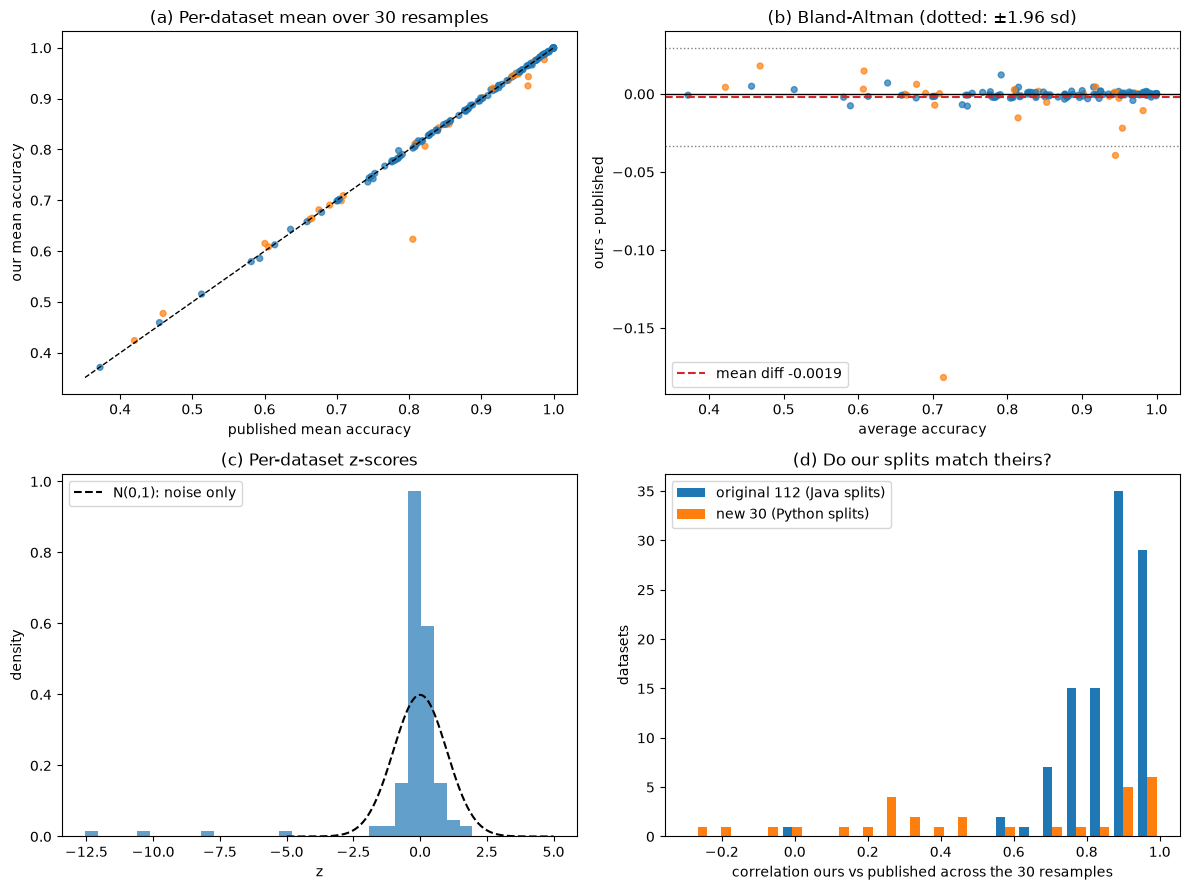

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
colors = per_dataset["group"].map({"original112": "C0", "new30": "C1"})

# (a) per-dataset mean accuracy: ours vs published
ax = axes[0, 0]
ax.scatter(per_dataset["published_mean"], per_dataset["ours_mean"], c=colors, alpha=0.7, s=18)
lo = per_dataset[["published_mean", "ours_mean"]].min().min() - 0.02
ax.plot([lo, 1], [lo, 1], "k--", linewidth=1)
ax.set(xlabel="published mean accuracy", ylabel="our mean accuracy", title="(a) Per-dataset mean over 30 resamples")

# (b) Bland-Altman: difference vs average, per dataset
ax = axes[0, 1]
avg = (per_dataset["published_mean"] + per_dataset["ours_mean"]) / 2
d = per_dataset["diff"]
ax.scatter(avg, d, c=colors, alpha=0.7, s=18)
ax.axhline(0, color="k", linewidth=1)
ax.axhline(d.mean(), color="C3", linestyle="--", label=f"mean diff {d.mean():+.4f}")
for k in (-1.96, 1.96):
    ax.axhline(d.mean() + k * d.std(), color="grey", linestyle=":", linewidth=1)
ax.set(xlabel="average accuracy", ylabel="ours - published", title="(b) Bland-Altman (dotted: ±1.96 sd)")
ax.legend()

# (c) z-scores vs the standard normal expected under pure noise
ax = axes[1, 0]
z = per_dataset["z"].dropna()
ax.hist(z, bins=30, density=True, alpha=0.7)
xs = np.linspace(-5, 5, 200)
ax.plot(xs, stats.norm.pdf(xs), "k--", label="N(0,1): noise only")
ax.set(xlabel="z", ylabel="density", title="(c) Per-dataset z-scores")
ax.legend()

# (d) split correlation per group
ax = axes[1, 1]
ax.hist([per_dataset.loc[orig, "split_corr"].dropna(), per_dataset.loc[new, "split_corr"].dropna()],
        bins=20, label=["original 112 (Java splits)", "new 30 (Python splits)"], color=["C0", "C1"])
ax.set(xlabel="correlation ours vs published across the 30 resamples", ylabel="datasets",
       title="(d) Do our splits match theirs?")
ax.legend()

plt.tight_layout()
plt.show()

## 8. Verdict for the accuracy claims

Reproducibility levels (Gundersen, via Semmelrock et al. 2025):
**outcome** = same numbers (within noise), **analysis** = same statistical conclusion, **interpretation** = same takeaway.
The numbers are filled in automatically; the level is our judgement - fill it in after reading sections 5-7.

In [11]:
verdict = pd.DataFrame([
    {"claim": "C1: mean accuracy on 142 datasets x 30 resamples", "paper": PAPER_MEAN_142,
     "ours": summary.loc["all 142, 30 resamples", "ours_mean"],
     "wilcoxon_p": summary.loc["all 142, 30 resamples", "wilcoxon_p"], "level": "TODO"},
    {"claim": "C2 (QUANT side): mean accuracy on the 112 original datasets", "paper": PAPER_MEAN_112,
     "ours": summary.loc["original 112, 30 resamples", "ours_mean"],
     "wilcoxon_p": summary.loc["original 112, 30 resamples", "wilcoxon_p"], "level": "TODO"},
])
verdict["diff"] = verdict["ours"] - verdict["paper"]
verdict.round(4)

,claim,paper,ours,wilcoxon_p,level,diff
0,C1: mean accuracy on 142 datasets x 30 resamples,0.8568,0.8549,0.0315,TODO,-0.0019
1,C2 (QUANT side): mean accuracy on the 112 orig...,0.8671,0.8668,0.0103,TODO,-0.0003


## 9. Save the tables (for the README and the report)

In [ ]:
per_dataset.round(6).to_csv(RUN_DIR / f"comparison_per_dataset_{RUN_NAME}.csv")
summary.round(6).to_csv(RUN_DIR / f"comparison_summary_{RUN_NAME}.csv")
print("saved to", RUN_DIR, "as comparison_*_" + RUN_NAME + ".csv")

## 10. Not possible with v0 results (needs other data or the v1 code)

- [ ] Bake-off redux's independent QUANT run as a third comparison (download the reference results).
- [ ] Seed noise on its own (v1: fixed seeds, resample 0 x 10 seeds).
- [ ] Balanced accuracy, AUROC, log loss (v1: `predict_proba`).
- [ ] Timing claims (v1: per-phase timers, single core).